# Team Tech 2, Task 2: home pitch-control share (Monica)

Forecast the home team's pitch-control share (TTI) over the **next 60 s**, every **5 s**, with leave-one-match-out validation.
This notebook also builds the **load features** (team high-speed running and distance over the past 60 s).

It uses only the shared `bramex` package and the raw DFL files.


**Outputs** (saved to `OUT_DIR` in your Drive):
- `load_features.csv`: load features on the 5 s grid
- `task2_comparison_table.csv`: baseline vs. + load vs. + all features
- `task2_mae_by_match.csv`: error for each held-out match
- `task2_error_by_match.png`: per-match figure
- `task2_coefficients_by_fold.csv`: standardized coefficients of the full model

Code developed with assistance from Claude (Anthropic) including adapting it to the team’s shared tables and debugging.

## 1. Setup

In [1]:
# Install the shared package (same as the team notebook)
import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/leonardoeng13/bramex-football-exertion-pitch-control.git"
try:
    import bramex
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{REPO_URL}"], check=True)
    import bramex

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bramex import CONFIG

# Same setting as the team notebook (D4): compute Voronoi and TTI pitch control
CONFIG["PITCH_CONTROL"] = ("voronoi", "tti")
CONFIG["HOLDOUT_MATCHES"] = []
print("bramex", bramex.__version__)

bramex 0.1.0


In [2]:
# Paths
from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/FootballMIT/Bundesliga"
CACHE_DIR = "/content/drive/MyDrive/FootballMIT/cache"
OUT_DIR = "/content/drive/MyDrive/FootballMIT/task2_outputs"

ENV = bramex.setup_environment(data=DATA_DIR, cache=CACHE_DIR)
MATCHES = bramex.discover_matches()
print(len(MATCHES), "matches:", list(MATCHES))

Mounted at /content/drive
environment  colab
data_dir     /content/drive/MyDrive/FootballMIT/Bundesliga
cache_dir    /content/drive/MyDrive/FootballMIT/cache/tables_408663779a
data_found   True
python       3.13.18
6 matches: ['J03WMX', 'J03WOH', 'J03WOY', 'J03WPY', 'J03WQQ', 'J03WR9']


## 2. Load the shared tables

In [3]:
# Only team_samples is needed: 5 samples per second, home pitch control, possession, ball, team load
T = bramex.load_tables(MATCHES)
TS = T.team_samples
print(TS.shape)
TS.head()

[1/6] J03WMX ready
[2/6] J03WOH ready
[3/6] J03WOY ready
[4/6] J03WPY ready
[5/6] J03WQQ ready
[6/6] J03WR9 ready
(172212, 18)


,match,half,sample,t,minute,inplay,poss_side,ball_x,ball_y,home_dir,home_voronoi,home_voronoi_ball,home_hsr,away_hsr,home_dist,away_dist,home_tti,home_tti_ball
0,J03WMX,firstHalf,0,0.0000,0,True,Away,0.1800,-0.1700,-1.0000,0.4669,0.4850,0.0000,0.0000,3.9340,4.2182,0.4750,0.5130
1,J03WMX,firstHalf,1,0.2000,0,True,Away,-2.6900,-0.2800,-1.0000,0.4675,0.4187,0.2210,0.0000,4.4487,4.3988,0.4784,0.4661
2,J03WMX,firstHalf,2,0.4000,0,True,Away,-5.5500,-0.4000,-1.0000,0.4697,0.3604,1.1397,0.0000,4.7918,5.0293,0.4803,0.4210
3,J03WMX,firstHalf,3,0.6000,0,True,Away,-8.4200,-0.5100,-1.0000,0.4769,0.3265,1.1819,0.6764,4.7937,5.7036,0.4802,0.3762
4,J03WMX,firstHalf,4,0.8000,0,True,Away,-11.2900,-0.6200,-1.0000,0.4798,0.2966,1.2031,1.1630,4.4807,6.1320,0.4790,0.3316


## 3. Task 2 code
The cell writes the module to a file so it can be imported (and committed to GitHub as is).

In [4]:
%%writefile task2_pitch_control.py
"""Team Tech 2, Task 2 (Monica): forecast the home team's pitch-control share
over the next 60 s, and build the team load features.

Works on T.team_samples from the bramex package (5 samples per second).
Shared rules: prediction every 5 s, 60 s horizon, past-only features,
leave-one-match-out validation, linear regression.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

HZ = 5                      # samples per second in team_samples
STEP = 5 * HZ               # one prediction every 5 s
HORIZON = 60 * HZ           # target: next 60 s
PAST = 60 * HZ              # features: past 60 s
NOW = 5 * HZ                # "current" share: last 5 s
MIN_TARGET = 12 * HZ        # need at least 12 s of in-play pitch control ahead
SHARE = "home_tti"          # main pitch-control measure (decision D4)

# Workstream B figure style (same as the team notebook, Part 6.4)
PURPLE, PINK = "#6250d6", "#d55181"
INK2, MUTED, SURF, GRID = "#52514e", "#898781", "#fcfcfb", "#e6e5e0"
_RC = {"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
       "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": INK2,
       "figure.facecolor": SURF, "axes.facecolor": SURF}

# Model inputs (the home-minus-away difference is saved too, but left out of the
# regression because it is an exact combination of the two HSR columns)
LOAD_FEATURES = ["L_home_hsr_60", "L_away_hsr_60", "L_home_dist_60", "L_away_dist_60"]
LOAD_FILE_COLUMNS = LOAD_FEATURES + ["L_hsr_diff_60"]
B_FEATURES = ["B_share_60", "B_share_ball_60", "B_voronoi_60",
              "B_home_poss_60", "B_ball_x_60", "B_inplay_60"]


# ------------------------------------------------------------------ helpers
def _window_mean(x, start, stop):
    """nanmean of x[start:stop] for each pair, and the count of non-missing values."""
    c = np.r_[0, np.cumsum(~np.isnan(x))]
    s = np.r_[0, np.cumsum(np.nan_to_num(x))]
    n = c[stop] - c[start]
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(n > 0, (s[stop] - s[start]) / np.maximum(n, 1), np.nan), n


def _window_sum(x, start, stop):
    s = np.r_[0, np.cumsum(np.nan_to_num(x))]
    return s[stop] - s[start]


# ------------------------------------------------------------------ table
def build_task2_table(team_samples):
    """One row per prediction time: target, current share, load and B features."""
    rows = []
    for (match, half), d in team_samples.groupby(["match", "half"], sort=True):
        d = d.sort_values("sample").reset_index(drop=True)
        n = len(d)
        inplay = d["inplay"].to_numpy(bool)
        share = np.where(inplay, d[SHARE].to_numpy(float), np.nan)
        share_ball = np.where(inplay, d[SHARE + "_ball"].to_numpy(float), np.nan)
        voronoi = np.where(inplay, d["home_voronoi"].to_numpy(float), np.nan)
        home_poss = np.where(inplay, (d["poss_side"] == "Home").to_numpy(float), np.nan)
        ball_x = np.where(inplay, d["ball_x"].to_numpy(float) * d["home_dir"].to_numpy(float), np.nan)

        # Prediction times: every 5 s, 60 s of past and 60 s ahead available, ball in play now
        k = np.arange(PAST, n - HORIZON, STEP)
        k = k[inplay[k]]
        if len(k) == 0:
            continue
        past0, now0, now1 = k - PAST, k - NOW + 1, k + 1
        fut0, fut1 = k + 1, k + 1 + HORIZON

        target, n_target = _window_mean(share, fut0, fut1)
        current, _ = _window_mean(share, now0, now1)
        out = pd.DataFrame({
            "match": match, "half": half, "sample": d["sample"].to_numpy()[k],
            "t": d["t"].to_numpy()[k], "target": target, "n_target": n_target,
            "current_share": current,
            # Load: team running over the past 60 s (m)
            "L_home_hsr_60": _window_sum(d["home_hsr"].to_numpy(float), past0, now1),
            "L_away_hsr_60": _window_sum(d["away_hsr"].to_numpy(float), past0, now1),
            "L_home_dist_60": _window_sum(d["home_dist"].to_numpy(float), past0, now1),
            "L_away_dist_60": _window_sum(d["away_dist"].to_numpy(float), past0, now1),
            # B: pitch control, possession and ball position over the past 60 s
            "B_share_60": _window_mean(share, past0, now1)[0],
            "B_share_ball_60": _window_mean(share_ball, past0, now1)[0],
            "B_voronoi_60": _window_mean(voronoi, past0, now1)[0],
            "B_home_poss_60": _window_mean(home_poss, past0, now1)[0],
            "B_ball_x_60": _window_mean(ball_x, past0, now1)[0],
            "B_inplay_60": _window_mean(inplay.astype(float), past0, now1)[0],
        })
        out["L_hsr_diff_60"] = out.L_home_hsr_60 - out.L_away_hsr_60
        rows.append(out)

    tab = pd.concat(rows, ignore_index=True)
    keep = (tab.n_target >= MIN_TARGET) & tab.current_share.notna()
    tab = tab[keep].reset_index(drop=True)
    # Rare gaps in the B features: fill with the current share or the match mean
    for c in ("B_share_60", "B_share_ball_60", "B_voronoi_60"):
        tab[c] = tab[c].fillna(tab.current_share)
    for c in ("B_home_poss_60", "B_ball_x_60"):
        tab[c] = tab[c].fillna(tab.groupby("match")[c].transform("mean"))
    return tab


def load_feature_table(tab):
    """The load features on the 5 s grid, saved for anyone who wants them."""
    cols = ["match", "half", "sample", "t"] + LOAD_FILE_COLUMNS
    return tab[cols].copy()


# ------------------------------------------------------------------ models
MODELS = {
    "Baseline: mean share": None,
    "Baseline: current share": None,
    "Current share (fitted)": ["current_share"],
    "+ load": ["current_share"] + LOAD_FEATURES,
    "+ all features": ["current_share"] + LOAD_FEATURES + B_FEATURES,
}
MAIN_BASELINE = "Baseline: mean share"        # the assignment's baseline, and the stronger of the two
REFERENCE = "Current share (fitted)"           # fair test of what load adds on top of the current share


def evaluate_lomo(tab):
    """Leave one match out. Returns predictions (one column per model) and per-match MAE."""
    pred = pd.DataFrame(index=tab.index)
    coefs = []
    for m in sorted(tab.match.unique()):
        test = tab.match == m
        train = ~test
        pred.loc[test, "Baseline: mean share"] = tab.loc[train, "target"].mean()
        pred.loc[test, "Baseline: current share"] = tab.loc[test, "current_share"]
        for name, cols in MODELS.items():
            if cols is None:
                continue
            fit = LinearRegression().fit(tab.loc[train, cols], tab.loc[train, "target"])
            pred.loc[test, name] = fit.predict(tab.loc[test, cols])
            if name == "+ all features":
                # Standardized coefficients: change in target (points) per 1 SD of the feature
                sd = tab.loc[train, cols].std()
                coefs.append(pd.Series(fit.coef_ * sd.to_numpy() * 100, index=cols, name=m))
    err = pred.sub(tab["target"], axis=0).abs() * 100          # in percentage points
    err["match"] = tab["match"]
    per_match = err.groupby("match").mean()
    return pred, per_match, pd.DataFrame(coefs)


def comparison_table(per_match, baseline=MAIN_BASELINE, reference=REFERENCE):
    """Same format for every task: error, change vs baseline, matches improved.
    Two extra columns compare + load and + all features with the fitted current share."""
    n = len(per_match)
    rows = []
    for name in per_match.columns:
        diff = per_match[name] - per_match[baseline]
        dref = per_match[name] - per_match[reference]
        later = name in ("+ load", "+ all features")
        rows.append({
            "Model": name,
            "MAE (points)": per_match[name].mean(),
            "Change vs baseline": np.nan if name == baseline else diff.mean(),
            "Change (%)": np.nan if name == baseline else 100 * diff.mean() / per_match[baseline].mean(),
            "Matches improved": "---" if name == baseline else f"{int((diff < 0).sum())} of {n}",
            "Change vs fitted current share": dref.mean() if later else np.nan,
            "Matches improved vs fitted": f"{int((dref < 0).sum())} of {n}" if later else "---",
        })
    return pd.DataFrame(rows)


def match_bootstrap(per_match, model, baseline=REFERENCE, n_boot=5000, seed=2980):
    """95% interval for the mean change vs a reference row, resampling matches."""
    diff = (per_match[model] - per_match[baseline]).to_numpy()
    rng = np.random.default_rng(seed)
    boots = rng.choice(diff, size=(n_boot, len(diff)), replace=True).mean(1)
    return np.percentile(boots, [2.5, 97.5])


# ------------------------------------------------------------------ figure
def per_match_figure(per_match, path, baseline=REFERENCE):
    """What load and the other features add: error minus the fitted current share, by held-out match."""
    d_load = per_match["+ load"] - per_match[baseline]
    d_all = per_match["+ all features"] - per_match[baseline]
    x = np.arange(len(per_match))
    with plt.rc_context(_RC):
        fig, ax = plt.subplots(figsize=(7, 3.6))
        ax.bar(x - 0.18, d_load, 0.36, color=PINK, label="+ load", zorder=3)
        ax.bar(x + 0.18, d_all, 0.36, color=PURPLE, label="+ all features", zorder=3)
        ax.axhline(0, color=INK2, lw=0.8, zorder=2)
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        ax.set_xticks(x)
        ax.set_xticklabels([m.replace("J03", "") for m in per_match.index])
        ax.set_ylabel("MAE minus fitted current share (points)")
        ax.set_title("Task 2. Home pitch-control share, next 60 s: what load adds, by held-out match",
                     loc="left", color=PURPLE, fontweight="bold", fontsize=10)
        ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
        fig.tight_layout()
        fig.savefig(path, dpi=200, bbox_inches="tight")
    return fig


# ------------------------------------------------------------------ run everything
def run_task2(team_samples, out_dir):
    from pathlib import Path
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)

    tab = build_task2_table(team_samples)
    load_feature_table(tab).to_csv(out / "load_features.csv", index=False)

    pred, per_match, coefs = evaluate_lomo(tab)
    table = comparison_table(per_match)
    lo, hi = match_bootstrap(per_match, "+ all features")
    lo_l, hi_l = match_bootstrap(per_match, "+ load")

    table.to_csv(out / "task2_comparison_table.csv", index=False)
    per_match.to_csv(out / "task2_mae_by_match.csv")
    coefs.to_csv(out / "task2_coefficients_by_fold.csv")
    per_match_figure(per_match, out / "task2_error_by_match.png")

    summary = {
        "prediction_times": len(tab),
        "per_match_rows": tab.groupby("match").size().to_dict(),
        "ci_change_load": (lo_l, hi_l),
        "ci_change_all": (lo, hi),
    }
    return tab, table, per_match, coefs, summary


Writing task2_pitch_control.py


## 4. Run

Prediction times per match: {'J03WMX': 638, 'J03WOH': 528, 'J03WOY': 552, 'J03WPY': 590, 'J03WQQ': 624, 'J03WR9': 630}
95 percent interval (match bootstrap), change vs fitted current share, + load:         -0.108 to 0.017 points
95 percent interval (match bootstrap), change vs fitted current share, + all features: -0.380 to -0.025 points


,Model,MAE (points),Change vs baseline,Change (%),Matches improved,Change vs fitted current share,Matches improved vs fitted
0,Baseline: mean share,10.7980,NaN,NaN,---,NaN,---
1,Baseline: current share,12.2300,1.4330,13.2680,1 of 6,NaN,---
2,Current share (fitted),9.3320,-1.4660,-13.5780,6 of 6,NaN,---
3,+ load,9.2900,-1.5080,-13.9650,6 of 6,-0.0420,3 of 6
4,+ all features,9.1230,-1.6750,-15.5080,6 of 6,-0.2080,5 of 6


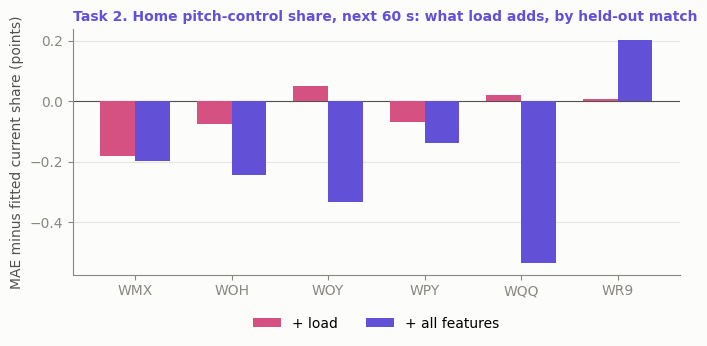

In [5]:
import importlib, task2_pitch_control as t2
importlib.reload(t2)

tab, table, per_match, coefs, summary = t2.run_task2(TS, OUT_DIR)
lo_l, hi_l = summary["ci_change_load"]
lo_a, hi_a = summary["ci_change_all"]
print("Prediction times per match:", summary["per_match_rows"])
print(f"95 percent interval (match bootstrap), change vs fitted current share, + load:         {lo_l:.3f} to {hi_l:.3f} points")
print(f"95 percent interval (match bootstrap), change vs fitted current share, + all features: {lo_a:.3f} to {hi_a:.3f} points")
table.round(3)

In [6]:
# Error for each held-out match (percentage points)
per_match.round(3)

,Baseline: mean share,Baseline: current share,Current share (fitted),+ load,+ all features
match,,,,,
J03WMX,12.0620,11.9080,9.9470,9.7650,9.7470
J03WOH,10.3630,12.1320,9.1690,9.0920,8.9250
J03WOY,9.9600,11.9700,8.8560,8.9060,8.5220
J03WPY,9.7740,12.1940,8.5600,8.4900,8.4220
J03WQQ,12.2690,13.9750,10.8670,10.8860,10.3300
J03WR9,10.3570,11.2030,8.5910,8.5990,8.7920


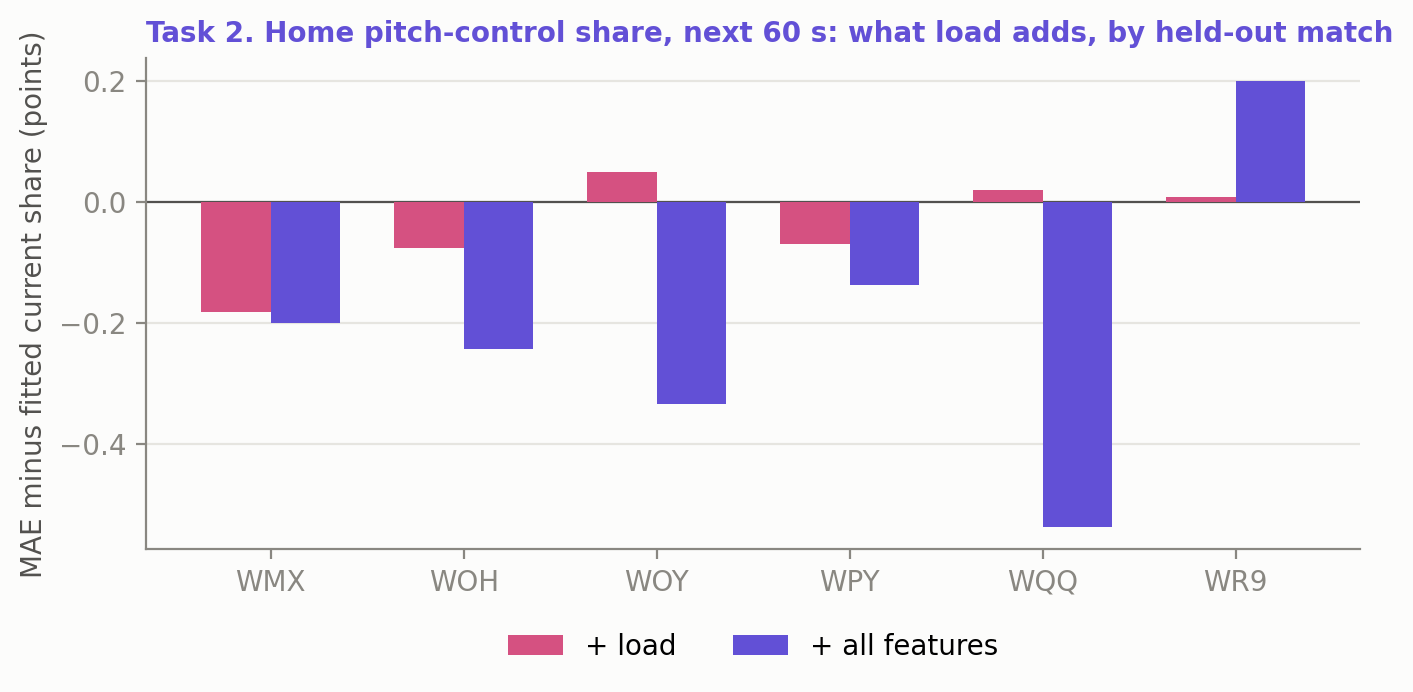

In [7]:
from IPython.display import Image, display
display(Image(f"{OUT_DIR}/task2_error_by_match.png"))

In [8]:
# Full model: change in the forecast (points) per 1 SD of each feature, mean and range across folds
pd.DataFrame({"mean": coefs.mean(), "min": coefs.min(), "max": coefs.max()}).round(2)

,mean,min,max
current_share,5.9200,5.3900,6.2200
L_home_hsr_60,1.6600,1.1700,2.1200
L_away_hsr_60,-1.8200,-1.9800,-1.7200
L_home_dist_60,-1.5600,-3.0100,-0.3400
L_away_dist_60,1.7800,1.4000,2.3100
B_share_60,5.1000,-3.5400,11.8400
B_share_ball_60,1.0400,0.1700,1.7600
B_voronoi_60,-5.1800,-11.8900,3.3800
B_home_poss_60,1.5100,0.4200,2.1700
B_ball_x_60,-0.7600,-0.9000,-0.5800


## 5. How to read the results

- **Main baseline: mean share** (the assignment's baseline). It beats the raw current share, because pitch control over 5 s jumps around.
- **Current share (fitted)** uses only the current share, pulled toward the average. It is the fair reference for the load question.
- **Change vs fitted current share:** what load (and then all features) adds on top of the current share. Near zero means load adds nothing.
- **Matches improved:** in how many held-out matches the model beat the row it is compared with.
- The figure shows the same comparison match by match. If load adds nothing, that is a finding: it supports *running more does not buy pitch control*.